In [1]:
import pandas as pd
import numpy as np

print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")

Pandas version: 3.0.5
NumPy version: 2.4.6


<h1>Lodaing The Dataset<h1>

In [2]:
# Load with MultiIndex headers (two rows of headers)
df = pd.read_excel('../data/raw/SEERA_cost_estimation_dataset.xlsx', header=[0, 1],keep_default_na=False, na_values="?" )

print("Dataset loaded successfully!")
print(f"Shape: {df.shape} rows x {df.shape[1]} columns")

Dataset loaded successfully!
Shape: (120, 76) rows x 76 columns


<h1> Dataset Structure</h1>

In [14]:
df.info

<bound method DataFrame.info of     General Information                                                    \
                 ProjID Year of project Organization id Organization type   
0                     1            2015               1                 1   
1                     2            2016              25                 5   
2                     3            2008               2                 5   
3                     4            2009              42                 4   
4                     5            2016              42                 4   
..                  ...             ...             ...               ...   
115                 116            2018              38                 1   
116                 117            1998               4                 4   
117                 118            2006              14                 2   
118                 119            2016              43                 6   
119                 120            2016     

In [3]:
print("Column structure (MultiIndex):")
print(df.columns)

Column structure (MultiIndex):
MultiIndex([('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            ('General Information', ...),
            (               'Size', ...),
            (               'Size', ...),
            (               'Size', ...),
            (             'Effort', ...),
            (             'Effort', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
            (        'Environment', ...),
   

<b>Flattening the columns for easier viewing<b>

In [4]:
df_flattened = df.copy()
df_flattened.columns = ['_'.join(col).strip() for col in df.columns.values]
print("Flattened column names:")
print(df_flattened.columns.tolist())

Flattened column names:
['General Information_ProjID', 'General Information_Year of project', 'General Information_Organization id', 'General Information_Organization type', 'General Information_Role in organization', 'General Information_Size of organization', 'General Information_Size of IT department', 'General Information_Customer organization type', 'General Information_Estimated  duration', 'General Information_Actual duration', 'General Information_% project gain (loss)', 'General Information_Development type', 'General Information_Application domain', 'Size_Object points', 'Size_Other sizing method', 'Size_Estimated size', 'Effort_Estimated effort', 'Effort_Actual effort', 'Environment_Contract maturity', 'Environment_Government policy impact', 'Environment_Economic instability impact', 'Environment_Organization management structure clarity', 'Environment_Developer hiring policy', 'Environment_Developer incentives policy', 'Environment_Developer training', 'Environment_Developm

<b>Data types</b>

In [5]:
print("Data types:")
print(df.dtypes)

Data types:
General Information  ProjID                        int64
                     Year of project               int64
                     Organization id               int64
                     Organization type             int64
                     Role in organization          int64
                                                  ...   
Product              Performance requirements    float64
                     Product complexity          float64
                     Security requirements       float64
                     Reliability requirements    float64
                     Specified H/W               float64
Length: 76, dtype: object


<b>Data types summary</b>

In [6]:
print("Data type summary:")
df.info()
print(df.dtypes.value_counts())

Data type summary:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 76 columns):
 #   Column                                                        Non-Null Count  Dtype  
---  ------                                                        --------------  -----  
 0   (General Information, ProjID)                                 120 non-null    int64  
 1   (General Information, Year of project)                        120 non-null    int64  
 2   (General Information, Organization id)                        120 non-null    int64  
 3   (General Information, Organization type)                      120 non-null    int64  
 4   (General Information, Role in organization)                   120 non-null    int64  
 5   (General Information, Size of organization)                   120 non-null    object 
 6   (General Information, Size of IT department)                  120 non-null    object 
 7   (General Information, Customer organization type)             1

<h1>1. Missing Values</h1>

In [8]:
print("Missing values per column:")
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

Missing values per column:
General Information  % project gain (loss)                             39
Developers           Team contracts                                    11
Product              Requirement accuracy level                         4
General Information  Customer organization type                         4
Project              Process reengineering                              3
Product              Product complexity                                 3
Environment          Organization management structure clarity          2
Size                 Object points                                      2
Project              Degree of software reuse                           2
Environment          Developer training                                 2
Product              Reliability requirements                           2
                     Specified H/W                                      2
Developers           Income satisfaction                                2
Product    

In [6]:
na_not_applicable = (df == "N/A").sum()
print("Columns with 'N/A' values:")
print(na_not_applicable[na_not_applicable > 0])

Columns with 'N/A' values:
General Information  Size of organization           8
                     Size of IT department          8
                     % project gain (loss)         17
Size                 Estimated size               107
Project              Outsourcing impact           108
                     Degree of standards usage     98
dtype: int64


In [10]:
missing_percent = (df.isnull().sum())/len(df)*100
print("Percentage of missing values per column:")
print(missing_percent[missing_percent > 0].sort_values(ascending=False))

Percentage of missing values per column:
General Information  % project gain (loss)                             32.500000
Developers           Team contracts                                     9.166667
General Information  Customer organization type                         3.333333
Product              Requirement accuracy level                         3.333333
Project              Process reengineering                              2.500000
Product              Product complexity                                 2.500000
Project              Degree of software reuse                           1.666667
Environment          Organization management structure clarity          1.666667
                     Developer training                                 1.666667
Developers           Income satisfaction                                1.666667
Size                 Object points                                      1.666667
Product              Comments within the code                       

<Axes: title={'center': 'Percentage of Missing Values'}>

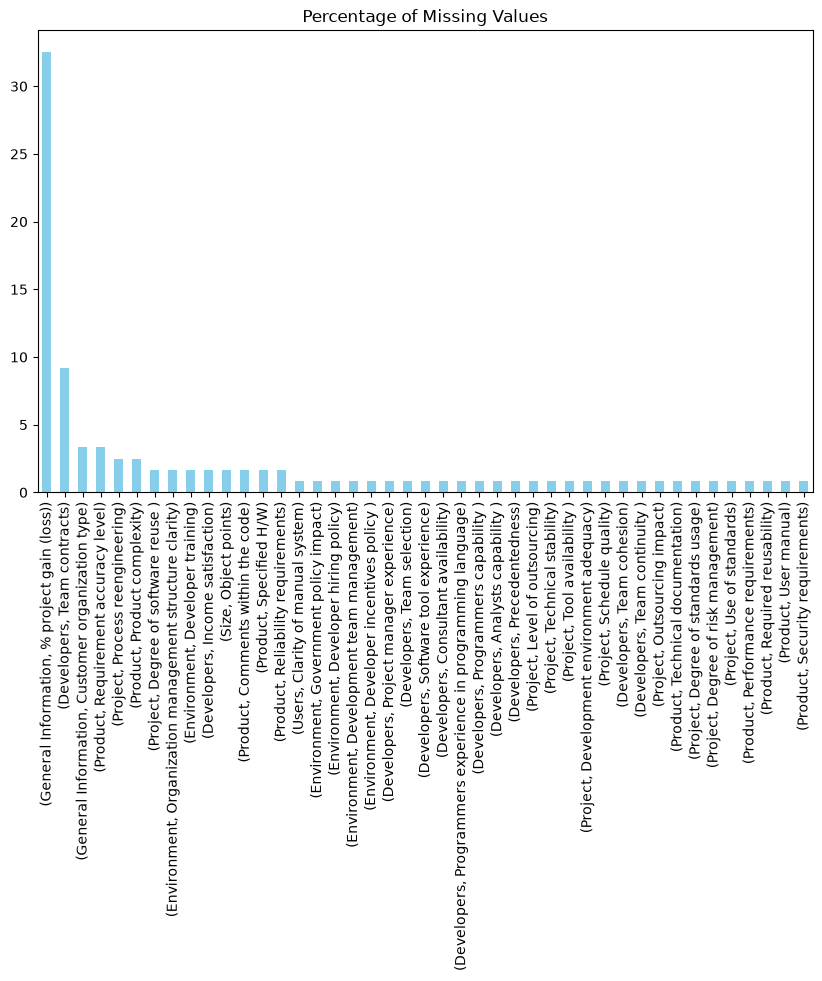

In [70]:
missing_percent[missing_percent > 0].sort_values(ascending=False).plot(kind='bar', color='skyblue', title='Percentage of Missing Values', figsize=(10, 6))

<h2>2. Outliers </h2>
To calculate the outliers, we used the IQR method <br>
We check only continuos columns

In [11]:
def profile_outliers_safe(df, columns=None):
    """
    Safely analyzes outliers column-by-column, ignoring non-numeric features.
    """
    # If no columns specified, automatically pick only numeric ones
    if columns is None:
        columns = df.select_dtypes(include=[np.number]).columns.tolist()
        
    analysis_results = []
    
    for col in columns:
        if col in df.columns:
            # CHECK: Skip if the column is text, category, object, or boolean
            if not np.issubdtype(df[col].dtype, np.number):
                print(f"Skipping column '{col}': It is not numerical ({df[col].dtype}).")
                continue
                
            # IQR Boundary Calculations
            Q1 = df[col].quantile(0.25)
            Q3 = df[col].quantile(0.75)
            IQR = Q3 - Q1
            lower_bound = Q1 - 1.5 * IQR
            upper_bound = Q3 + 1.5 * IQR
            
            # Isolate outliers
            outlier_mask = (df[col] < lower_bound) | (df[col] > upper_bound)
            outliers_series = df.loc[outlier_mask, col]
            
            analysis_results.append({
                'Column': col,
                'Outlier Count': int(outlier_mask.sum()),
                'Sum of Outliers': float(outliers_series.sum()),
                'Actual Values': outliers_series.tolist()
            })
            
    return pd.DataFrame(analysis_results)
continuous_columns = [
    ('General Information', 'Year of project'),
    ('General Information', 'Estimated  duration'),
    ('General Information', 'Actual duration'),
    ('Size', 'Object points'),
    ('Effort', 'Estimated effort'),
    ('Effort', 'Actual effort'),
    ('Developers', 'Team size'),
    ('Developers', 'Dedicated team members'),
    ('Developers', 'Daily working hours'),
    ('Developers', 'Team continuity ')
]

outlier_data = profile_outliers_safe(df, continuous_columns)
print("=== OUTLIER ANALYSIS REPORT ===")
for col, info in outlier_data.iterrows():
     print(f"Column indexed#{col} {info['Column']}: Found {info['Outlier Count']} outliers.")
     print(f" -> Actual Values: {info['Actual Values']}\n")

=== OUTLIER ANALYSIS REPORT ===
Column indexed#0 ('General Information', 'Year of project'): Found 2 outliers.
 -> Actual Values: [1994, 1993]

Column indexed#1 ('General Information', 'Estimated  duration'): Found 3 outliers.
 -> Actual Values: [20.0, 15.0, 18.0]

Column indexed#2 ('General Information', 'Actual duration'): Found 12 outliers.
 -> Actual Values: [24.0, 45.0, 36.0, 25.0, 24.0, 24.0, 36.0, 24.0, 36.0, 48.0, 24.0, 36.0]

Column indexed#3 ('Size', 'Object points'): Found 3 outliers.
 -> Actual Values: [1100.0, 800.0, 1700.0]

Column indexed#4 ('Effort', 'Estimated effort'): Found 8 outliers.
 -> Actual Values: [19008, 50688, 25344, 14784, 17600, 26928, 31680, 14256]

Column indexed#5 ('Effort', 'Actual effort'): Found 11 outliers.
 -> Actual Values: [38016.0, 24255.0, 35640.0, 76032.0, 29040.0, 38016.0, 22176.0, 28160.0, 44880.0, 33792.0, 79200.0]

Column indexed#6 ('Developers', 'Team size'): Found 9 outliers.
 -> Actual Values: [48, 12, 12, 12, 11, 25, 18, 12, 45]

Colum

<h2>Unique Values</h2>

In [ ]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
df.nunique(dropna=False).sort_values()

In [19]:
df.nunique(dropna=False)[df.nunique(dropna=False) == 1]

Series([], dtype: int64)

In [17]:
for col in df.columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False).head(15))


--- ('General Information', 'ProjID') ---
(General Information, ProjID)
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
Name: count, dtype: int64

--- ('General Information', 'Year of project') ---
(General Information, Year of project)
2016    19
2018    15
2017    12
2015     8
2009     7
2014     7
2012     6
2006     6
2013     5
2019     5
2001     4
2008     3
2010     3
2011     3
2004     3
Name: count, dtype: int64

--- ('General Information', 'Organization id') ---
(General Information, Organization id)
11    16
6     11
42     8
3      8
5      8
14     6
8      4
13     4
18     4
35     4
2      3
7      3
9      3
4      2
12     2
Name: count, dtype: int64

--- ('General Information', 'Organization type') ---
(General Information, Organization type)
5    65
4    26
2     8
3     6
7     5
1     4
8     4
6     2
Name: count, dtype: int64

--- ('General Information', 'Role in organization') ---
(Gene

<h2>Duplicates</h2>

In [18]:
df.duplicated().sum()

np.int64(0)

<h2>Inconsistant Categorical Data</h2>

<h2> Columns inspection: categrical columns</h2>

In [35]:
# Categorical/options attributes explicitly documented in the
# SEERA_dataset__sub_attribute_codes.pdf, matched to the actual
# MultiIndex column names (including exact spacing) in df.

categorical_columns = [
    # General Information
    ("General Information", "Organization type"),
    ("General Information", "Role in organization"),
    ("General Information", "Customer organization type"),
    ("General Information", "Size of organization"),
    ("General Information", "Size of IT department"),
    ("General Information", "Application domain"),
    ("General Information", "Development type"),

    # Environment
    ("Environment", "Government policy impact"),
    ("Environment", "Developer hiring policy"),
    ("Environment", "Organization management structure clarity"),
    ("Environment", "Developer incentives policy "),   # trailing space in df
    ("Environment", "Developer training"),

    # Users
    ("Users", "Top management opinion of previous system"),
    ("Users", "Clarity of manual system"),
    ("Users", "User computer experience"),
    ("Users", "Users stability"),
    ("Users", "Requirements flexibility"),

    # Developers
    ("Developers", "Project manager experience"),
    ("Developers", "Consultant availability"),
    ("Developers", "DBMS  expert availability"),        # double space in df
    ("Developers", "Software tool experience"),
    ("Developers", "Programmers experience in programming language"),
    ("Developers", "Team selection"),
    ("Developers", "Income satisfaction"),

    # Project
    ("Project", "Schedule quality"),
    ("Project", "Programming language used"),
    ("Project", "DBMS used"),
    ("Project", "Methodology"),
    ("Project", "Technical stability"),
    ("Project", "Open source software"),
    ("Project", "Level of outsourcing"),
    ("Project", "Outsourcing impact"),
    ("Project", "Degree of software reuse "),           # trailing space in df
    ("Project", "Use of standards"),
    ("Project", "Process reengineering"),

    # Product
    ("Product", "Requirement accuracy level"),
    ("Product", "Technical documentation"),
    ("Product", "Comments within the code"),
    ("Product", "User manual"),
    ("Product", "Required reusability"),
    ("Product", "Product complexity"),
    ("Product", "Reliability requirements"),
    ("Product", "Specified H/W"),
]

for col in categorical_columns:
    if col in df.columns:
        print(f"\n--- {col} ---")
        counts = df[col].value_counts(dropna=False)
        percentages = df[col].value_counts(dropna=False, normalize=True) * 100
    
        print(pd.DataFrame({
            "Count": counts,
            "Percentage": percentages.round(2)}))
    else:
        print(f"\nColumn not found in df: {col}")

# Columns not documented in this codes PDF — verify their coding
# in the main SEERA documentation before treating as categorical.
undocumented = [
    ("Environment", "Contract maturity"),
    ("Environment", "Economic instability impact"),
    ("Environment", "Development team management"),
    ("Users", "Top management support"),
    ("Users", "User resistance"),
    ("Users", "Requirment stability"),
    ("Developers", "Precedentedness"),
    ("Developers", "Programmers capability "),
    ("Developers", "Analysts capability "),
    ("Developers", "Team contracts"),
    ("Developers", "Team continuity "),
    ("Developers", "Team cohesion"),
    ("Project", "Development environment adequacy"),
    ("Project", "Tool availability "),
    ("Project", "Degree of risk management"),
    ("Project", "Degree of standards usage"),
    ("Product", "Performance requirements"),
    ("Product", "Security requirements"),
]
print("\n\n=== Columns NOT covered in this codes file (check separately) ===")
for col in undocumented:
    if col in df.columns:
        print(col)


--- ('General Information', 'Organization type') ---
                                          Count  Percentage
(General Information, Organization type)                   
5                                            65       54.17
4                                            26       21.67
2                                             8        6.67
3                                             6        5.00
7                                             5        4.17
1                                             4        3.33
8                                             4        3.33
6                                             2        1.67

--- ('General Information', 'Role in organization') ---
                                             Count  Percentage
(General Information, Role in organization)                   
2                                               76       63.33
1                                               32       26.67
4                                    

<h2> Actual Effort: Target Variable Analysis</h2>

In [44]:
actual_effort = df[("Effort", "Actual effort")]

print(f"Mean of actual effort is: {actual_effort.mean():.2f}")
print(f"Median is: {actual_effort.median():.2f}")
print(f"Mode value is: {actual_effort.mode().iloc[0]:.2f}")


Mean of actual effort is: 9060.93
Median is: 4576.00
Mode value is: 3168.00


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

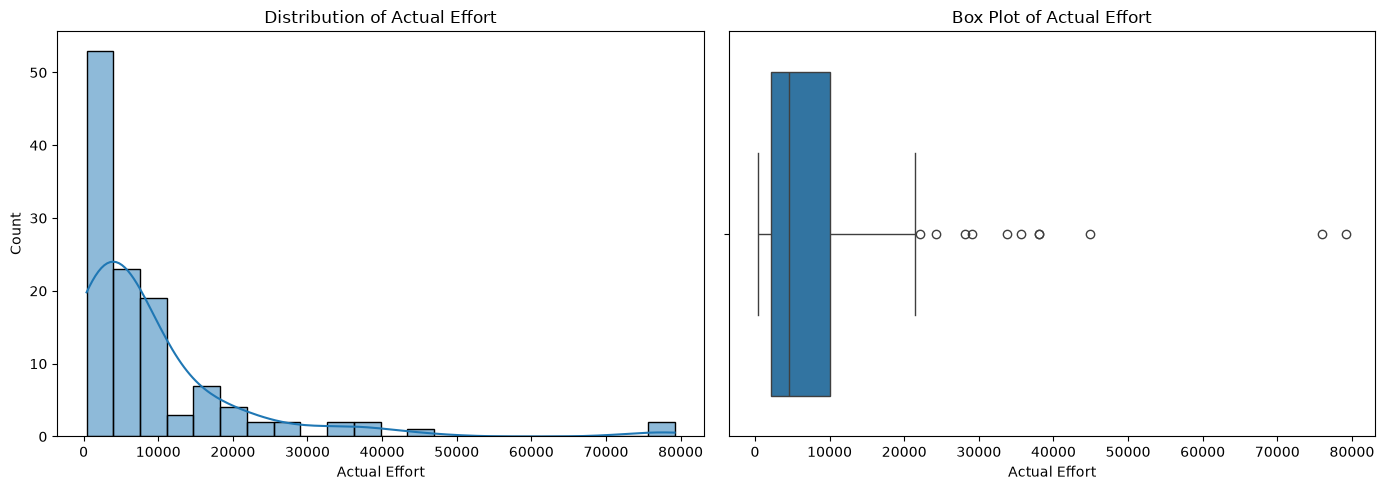

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[("Effort", "Actual effort")].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Distribution of Actual Effort')
axes[0].set_xlabel('Actual Effort')

sns.boxplot(x=df[("Effort", "Actual effort")].dropna(), ax=axes[1])
axes[1].set_title('Box Plot of Actual Effort')
axes[1].set_xlabel('Actual Effort')
plt.tight_layout()
plt.show()

In [60]:
from scipy.stats import skew, kurtosis

In [62]:
target_skew = df[("Effort", "Actual effort")].dropna().skew()
target_kurt = df[("Effort", "Actual effort")].dropna().kurtosis()

print(f"Skewness: {target_skew:.3f}")
print(f"Kurtosis: {target_kurt:.3f}")

Skewness: 3.345
Kurtosis: 14.067


Min value: 396.0
Values <= 0: 0


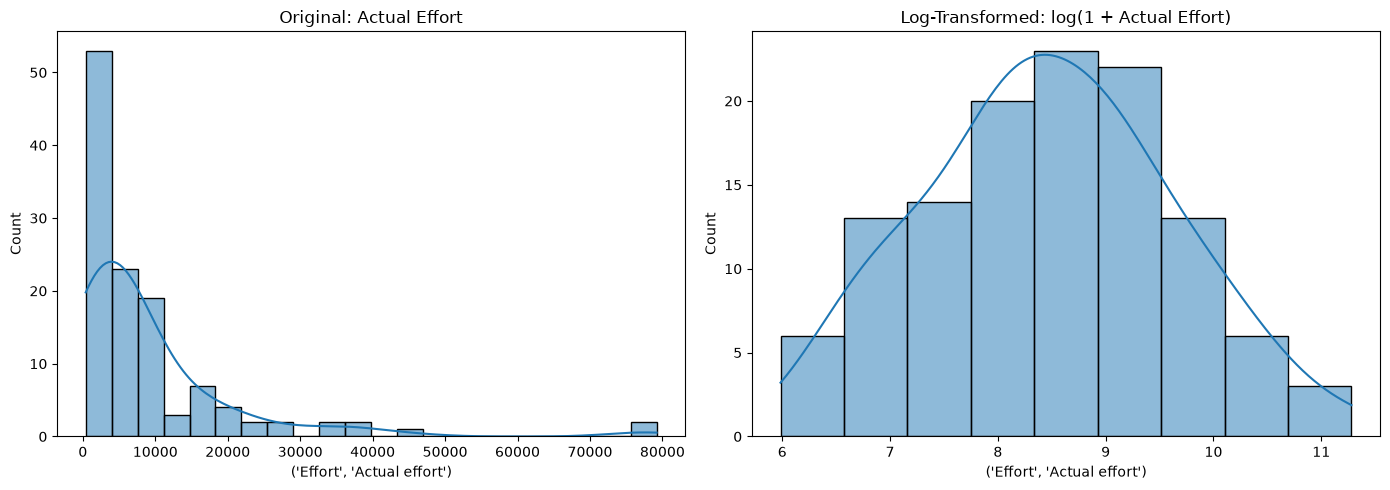

Original skewness: 3.345
Log-transformed skewness: 0.097


In [63]:
# Check for zero/negative values first (step 5, do this before log)
print(f"Min value: {df[('Effort', 'Actual effort')].min()}")
print(f"Values <= 0: {(df[('Effort', 'Actual effort')] <= 0).sum()}")

# Apply log1p and compare
log_effort = np.log1p(df[("Effort", "Actual effort")].dropna())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df[("Effort", "Actual effort")].dropna(), kde=True, ax=axes[0])
axes[0].set_title('Original: Actual Effort')

sns.histplot(log_effort, kde=True, ax=axes[1])
axes[1].set_title('Log-Transformed: log(1 + Actual Effort)')

plt.tight_layout()
plt.show()

log_skew = log_effort.skew()
print(f"Original skewness: {target_skew:.3f}")
print(f"Log-transformed skewness: {log_skew:.3f}")

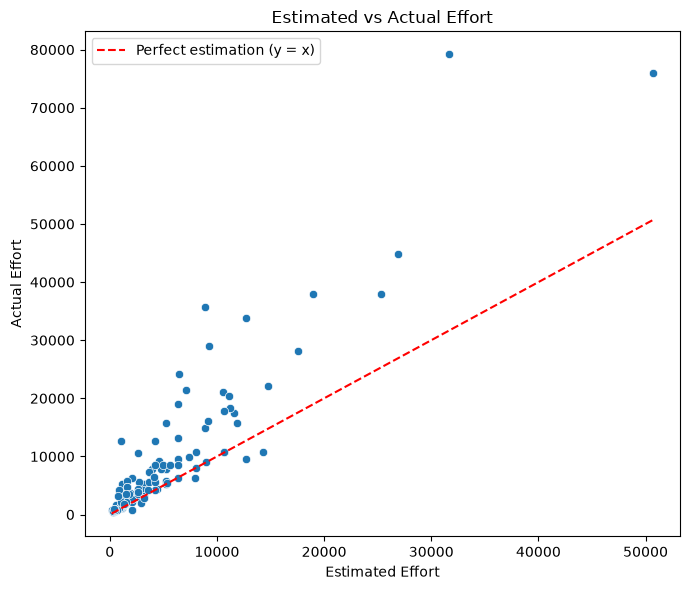

count     81
unique    31
top        0
freq      30
Name: (General Information, % project gain (loss)), dtype: int64


In [65]:
est_col = ('Effort', 'Estimated effort')

fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(x=df[est_col], y=df[("Effort", "Actual effort")], ax=ax)
ax.plot([df[est_col].min(), df[est_col].max()],
        [df[est_col].min(), df[est_col].max()],
        'r--', label='Perfect estimation (y = x)')
ax.set_xlabel('Estimated Effort')
ax.set_ylabel('Actual Effort')
ax.set_title('Estimated vs Actual Effort')
ax.legend()
plt.tight_layout()
plt.show()

# Quick numeric check using existing column
gain_loss_col = ('General Information', '% project gain (loss)')
print(df[gain_loss_col].describe())

In [66]:
gain_loss_col = ('General Information', '% project gain (loss)')
print(df[gain_loss_col].unique())

[nan 0 -0.16666666666666666 -0.17444444444444446 -0.25 'N/A'
 0.6296296296296297 -1.0215633423180592 0.16647058823529412 0.25 0.2 -1
 -0.04352941176470588 0.036470588235294116 0.05647058823529412
 -1.2222222222222223 0.026470588235294117 0.4533333333333333
 0.11647058823529412 0.08647058823529412 -0.013529411764705882
 0.4115384615384615 -0.21212121212121213 -0.13333333333333333 0.43
 0.07647058823529412 0.09375 0.5 -0.14285714285714285 0.3333333333333333
 -0.2222222222222222 -1.5]
